# Fiabilité conditionnelle des deux prévisions simples

**Question :** lorsque `RV5` est élevée, la volatilité historique 20 réduit-elle les sous-estimations par rapport à la constante, ou son avantage moyen vient-il surtout des dates ordinaires ?

Analyse exploratoire, rétrospective et limitée aux 1 001 prévisions de 2016–2019 déjà examinées. Aucun nouveau modèle, aucune nouvelle donnée et aucun ajustement.

## 1. Reconstitution exacte des prévisions existantes

In [1]:
from hashlib import sha256
from io import BytesIO, StringIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SOURCE_URL = ('https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/'
              'F-F_Research_Data_Factors_daily_CSV.zip')
EXPECTED_SHA256 = '2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db'
SNAPSHOT_FILENAME = (
    'F-F_Research_Data_Factors_daily_202608_'
    f'sha256-{EXPECTED_SHA256}.zip'
)
HORIZON = 5
HISTORICAL_WINDOW = 20
ANNUALIZATION_DAYS = 252
plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
snapshot_candidates = [
    Path('data/raw/fama_french') / SNAPSHOT_FILENAME,
    Path('../data/raw/fama_french') / SNAPSHOT_FILENAME,
]
local_snapshot = next((path for path in snapshot_candidates if path.is_file()), None)
if local_snapshot is not None:
    archive_bytes = local_snapshot.read_bytes()
    data_origin = local_snapshot.as_posix()
else:
    with urlopen(SOURCE_URL, timeout=60) as response:
        archive_bytes = response.read()
    data_origin = SOURCE_URL
assert sha256(archive_bytes).hexdigest() == EXPECTED_SHA256

with ZipFile(BytesIO(archive_bytes)) as archive:
    text = archive.read(archive.namelist()[0]).decode('utf-8-sig')
lines = text.splitlines()
header_index = next(i for i, line in enumerate(lines) if line.strip().startswith(',Mkt-RF'))
data_lines = [lines[header_index]]
for line in lines[header_index + 1:]:
    first_field = line.split(',', 1)[0].strip()
    if len(first_field) == 8 and first_field.isdigit():
        data_lines.append(line)
    else:
        break
factors = pd.read_csv(StringIO('\n'.join(data_lines)))
factors = factors.rename(columns={factors.columns[0]: 'date'})
factors['date'] = pd.to_datetime(factors['date'].astype(str), format='%Y%m%d')
factors = factors.set_index('date')
market_return = (factors['Mkt-RF'] + factors['RF']) / 100

future_returns = pd.concat(
    {f'r_t_plus_{k}': market_return.shift(-k) for k in range(1, HORIZON + 1)},
    axis=1,
)
rv_5 = np.sqrt((ANNUALIZATION_DAYS / HORIZON) * future_returns.pow(2).sum(axis=1, min_count=HORIZON))
hist_vol_20 = np.sqrt(
    (ANNUALIZATION_DAYS / HISTORICAL_WINDOW)
    * market_return.pow(2).rolling(HISTORICAL_WINDOW, min_periods=HISTORICAL_WINDOW).sum()
)
dates = factors.index.to_series(index=factors.index)
data = pd.DataFrame({
    'rv_5': rv_5,
    'hist_vol_20': hist_vol_20,
    'target_start': dates.shift(-1),
    'target_end': dates.shift(-HORIZON),
})
train = data.loc[(data.index >= '1990-01-01') & (data.target_end <= '2015-12-31')].dropna().copy()
evaluation = data.loc[(data.index >= '2016-01-01') & (data.target_end <= '2019-12-31')].dropna().copy()

predictions = evaluation[['rv_5', 'target_start', 'target_end']].copy()
predictions['constante'] = train['rv_5'].mean()
predictions['historique_20'] = evaluation['hist_vol_20']
for label in ['constante', 'historique_20']:
    predictions[f'erreur_{label}'] = 100 * (predictions[label] - predictions['rv_5'])
    predictions[f'erreur_absolue_{label}'] = predictions[f'erreur_{label}'].abs()
    predictions[f'erreur_carrée_{label}'] = predictions[f'erreur_{label}'].pow(2)
    predictions[f'sous_estimation_{label}'] = (-predictions[f'erreur_{label}']).clip(lower=0)

assert len(train) == 6548 and len(predictions) == 1001
assert predictions.target_end.max() <= pd.Timestamp('2019-12-31')
assert np.isclose(predictions.erreur_absolue_constante.mean(), 7.054, atol=.001)
assert np.isclose(predictions.erreur_absolue_historique_20.mean(), 4.839, atol=.001)
print(f'Origine : {data_origin}')
print(f'Apprentissage : {train.index.min().date()} → {train.index.max().date()} ({len(train):,})')
print(f'Évaluation : {predictions.index.min().date()} → {predictions.index.max().date()} ({len(predictions):,})')
print(f'Constante : {100 * predictions.constante.iloc[0]:.3f} % annualisé')

Origine : data/raw/fama_french/F-F_Research_Data_Factors_daily_202608_sha256-2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db.zip
Apprentissage : 1990-01-02 → 2015-12-23 (6,548)
Évaluation : 2016-01-04 → 2019-12-23 (1,001)
Constante : 14.775 % annualisé


## 2. Seuils fixés sur 1990–2015

Les quatre seuils sont les quintiles de `RV5` dans l'apprentissage. Ils sont non paramétriques, non optimisés sur 2016–2019 et donnent cinq niveaux initialement équiprobables. `Q5` signifie « élevée relativement à 1990–2015 », pas crise, perte ou régime économique. Le niveau est connu seulement après réalisation de `RV5` : cette analyse n'est pas un détecteur disponible à `t`.

In [3]:
quantile_probabilities = [.20, .40, .60, .80]
thresholds = 100 * train['rv_5'].quantile(quantile_probabilities)
labels = ['Q1', 'Q2', 'Q3', 'Q4', 'Q5']
predictions['niveau_rv5'] = pd.cut(
    100 * predictions['rv_5'],
    bins=[-np.inf, *thresholds.to_list(), np.inf],
    labels=labels,
    include_lowest=True,
)
assert predictions['niveau_rv5'].notna().all()

threshold_table = pd.DataFrame({
    'quantile_apprentissage': ['20 %', '40 %', '60 %', '80 %'],
    'seuil_rv5_pct_annualisé': thresholds.to_numpy(),
})
print(threshold_table.round(3).to_string(index=False))
print('\nEffectifs 2016–2019 selon ces seuils :')
print(predictions['niveau_rv5'].value_counts(sort=False).to_string())

quantile_apprentissage  seuil_rv5_pct_annualisé
                  20 %                    7.742
                  40 %                   10.492
                  60 %                   14.126
                  80 %                   19.815

Effectifs 2016–2019 selon ces seuils :
niveau_rv5
Q1    399
Q2    206
Q3    174
Q4     91
Q5    131


## 3. Résultats conditionnels et épisodes distincts

Un épisode est une suite maximale de dates d'origine consécutives appartenant au même niveau. Il réduit la confusion entre nombre de lignes et nombre de séquences, sans rendre les épisodes statistiquement indépendants.

In [4]:
def episode_summary(frame, level):
    mask = frame['niveau_rv5'].eq(level)
    starts = mask & ~mask.shift(fill_value=False)
    episode_id = starts.cumsum()
    lengths = mask[mask].groupby(episode_id[mask]).size()
    return pd.Series({
        'observations': int(mask.sum()),
        'épisodes': int(len(lengths)),
        'longueur_médiane': lengths.median(),
        'longueur_maximale': lengths.max(),
    })

episode_table = pd.DataFrame({level: episode_summary(predictions, level) for level in labels}).T
print(episode_table.to_string())

def conditional_metrics(frame, forecast):
    error = frame[f'erreur_{forecast}']
    shortfall = frame[f'sous_estimation_{forecast}']
    positive_shortfall = shortfall[shortfall > 0]
    return pd.Series({
        'n': len(frame),
        'MAE': error.abs().mean(),
        'RMSE': np.sqrt(error.pow(2).mean()),
        'erreur_signée': error.mean(),
        'sous_estimation_pct': 100 * (error < 0).mean(),
        'sous_estimation_moyenne_toutes_dates': shortfall.mean(),
        'ampleur_moyenne_si_sous_estimation': positive_shortfall.mean() if len(positive_shortfall) else 0,
        'sous_estimation_maximale': shortfall.max(),
    })

conditional_rows = []
paired_rows = []
for level, group in predictions.groupby('niveau_rv5', observed=True):
    for forecast in ['constante', 'historique_20']:
        row = conditional_metrics(group, forecast)
        row['niveau_rv5'] = level
        row['prévision'] = forecast
        conditional_rows.append(row)
    paired_rows.append({
        'niveau_rv5': level,
        'n': len(group),
        'gain_MAE_hist20': (group.erreur_absolue_constante - group.erreur_absolue_historique_20).mean(),
        'gain_RMSE_hist20': (
            np.sqrt(group.erreur_carrée_constante.mean())
            - np.sqrt(group.erreur_carrée_historique_20.mean())
        ),
        'gain_MSE_hist20': (group.erreur_carrée_constante - group.erreur_carrée_historique_20).mean(),
        'gain_sous_estimation_hist20': (group.sous_estimation_constante - group.sous_estimation_historique_20).mean(),
    })
conditional_table = pd.DataFrame(conditional_rows).set_index(['niveau_rv5', 'prévision'])
paired_table = pd.DataFrame(paired_rows).set_index('niveau_rv5')
paired_table['contribution_gain_MAE_global'] = (
    paired_table['n'] / len(predictions) * paired_table['gain_MAE_hist20']
)
print('Métriques par niveau (points de volatilité annualisée) :')
print(conditional_table.round(3).to_string())
print('\nDifférences appariées ; positif = avantage historique 20 :')
print(paired_table.round(3).to_string())

    observations  épisodes  longueur_médiane  longueur_maximale
Q1         399.0      56.0               7.0               29.0
Q2         206.0      79.0               2.0                6.0
Q3         174.0      62.0               2.0               10.0
Q4          91.0      38.0               2.0                5.0
Q5         131.0      21.0               5.0               20.0
Métriques par niveau (points de volatilité annualisée) :
                              n     MAE    RMSE  erreur_signée  sous_estimation_pct  sous_estimation_moyenne_toutes_dates  ampleur_moyenne_si_sous_estimation  sous_estimation_maximale
niveau_rv5 prévision                                                                                                                                                                   
Q1         constante      399.0   9.338   9.451          9.338                0.000                                 0.000                               0.000                     0.000
       

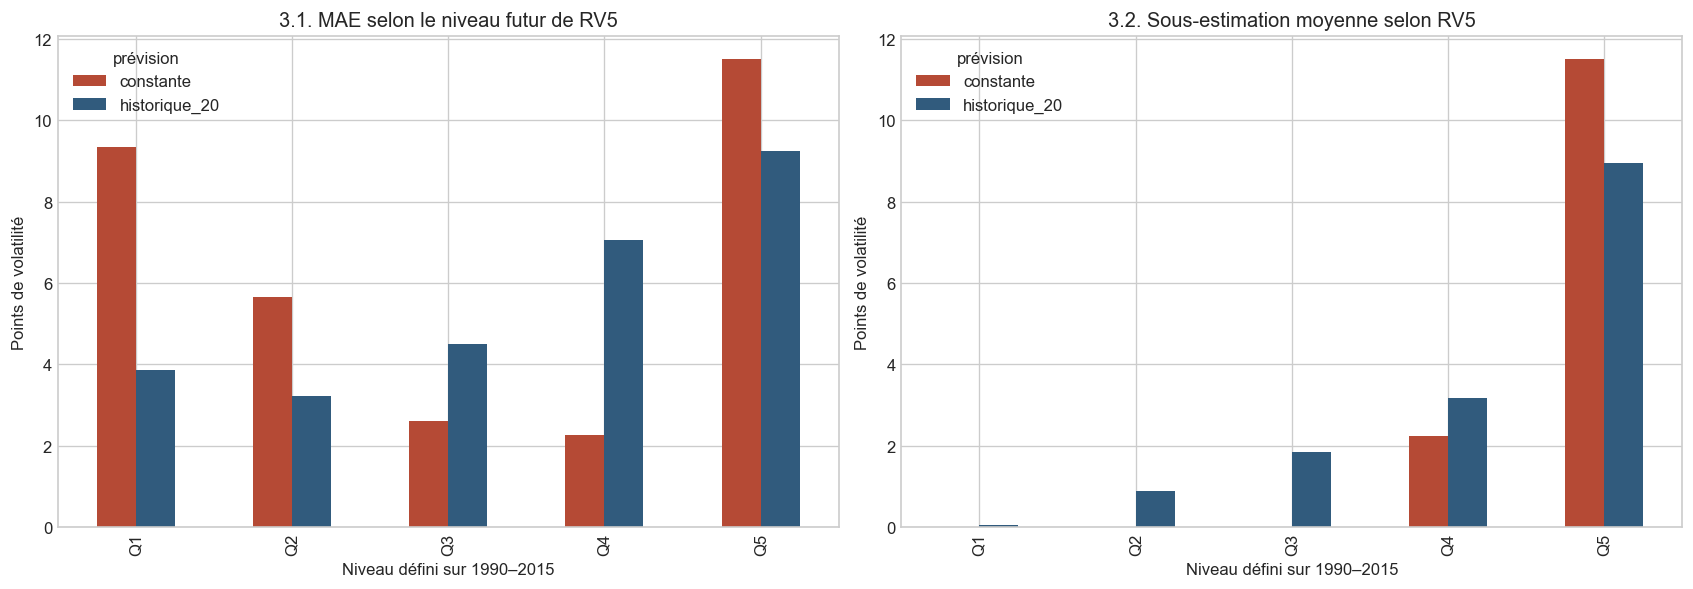

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
mae_plot = conditional_table['MAE'].unstack('prévision')
mae_plot.plot.bar(ax=axes[0], color=['#b54a35', '#315b7d'])
axes[0].set(title='3.1. MAE selon le niveau futur de RV5', xlabel='Niveau défini sur 1990–2015', ylabel='Points de volatilité')
under_plot = conditional_table['sous_estimation_moyenne_toutes_dates'].unstack('prévision')
under_plot.plot.bar(ax=axes[1], color=['#b54a35', '#315b7d'])
axes[1].set(title='3.2. Sous-estimation moyenne selon RV5', xlabel='Niveau défini sur 1990–2015', ylabel='Points de volatilité')
plt.show()

## 4. Sensibilité aux cinq décalages non chevauchants

Pour chaque décalage `0…4`, une origine sur cinq est retenue. Deux cibles successives du même sous-échantillon ne partagent alors aucun rendement. Les cinq résultats sont rapportés : aucun décalage favorable n'est sélectionné.

In [6]:
offset_rows = []
for offset in range(HORIZON):
    spaced = predictions.iloc[offset::HORIZON].copy()
    assert (spaced.target_start.iloc[1:].to_numpy() > spaced.target_end.iloc[:-1].to_numpy()).all()
    high = spaced.loc[spaced.niveau_rv5.eq('Q5')]
    row = {'décalage': offset, 'n_total': len(spaced), 'n_Q5': len(high)}
    for forecast in ['constante', 'historique_20']:
        metrics = conditional_metrics(high, forecast)
        row[f'MAE_{forecast}'] = metrics['MAE']
        row[f'RMSE_{forecast}'] = metrics['RMSE']
        row[f'sous_estimation_pct_{forecast}'] = metrics['sous_estimation_pct']
        row[f'sous_estimation_moyenne_{forecast}'] = metrics['sous_estimation_moyenne_toutes_dates']
        row[f'sous_estimation_max_{forecast}'] = metrics['sous_estimation_maximale']
    row['gain_MAE_hist20'] = row['MAE_constante'] - row['MAE_historique_20']
    row['gain_RMSE_hist20'] = row['RMSE_constante'] - row['RMSE_historique_20']
    row['gain_sous_estimation_hist20'] = (
        row['sous_estimation_moyenne_constante'] - row['sous_estimation_moyenne_historique_20']
    )
    offset_rows.append(row)
offset_table = pd.DataFrame(offset_rows).set_index('décalage')
print(offset_table.round(3).to_string())
print('\nÉtendue des gains sur Q5 ; positif = avantage historique 20 :')
print(offset_table[['gain_MAE_hist20', 'gain_RMSE_hist20', 'gain_sous_estimation_hist20']].agg(['min', 'max']).round(3).to_string())

          n_total  n_Q5  MAE_constante  RMSE_constante  sous_estimation_pct_constante  sous_estimation_moyenne_constante  sous_estimation_max_constante  MAE_historique_20  RMSE_historique_20  sous_estimation_pct_historique_20  sous_estimation_moyenne_historique_20  sous_estimation_max_historique_20  gain_MAE_hist20  gain_RMSE_hist20  gain_sous_estimation_hist20
décalage                                                                                                                                                                                                                                                                                                                                                                   
0             201    25         11.605          13.106                          100.0                             11.605                         31.199              9.394              12.513                             92.000                                  9.177        

## 5. Interprétation limitée

`Q5` désigne une volatilité future élevée relativement à l'apprentissage, observée après `t`. Ce n'est ni une information disponible en temps réel, ni une crise, ni nécessairement une perte financière : `RV5` ignore le signe des rendements.

Les résultats décrivent la performance conditionnelle des deux règles sur une période déjà explorée. Les épisodes restent historiquement liés et les cinq sous-échantillons non chevauchants sont des sensibilités descriptives, pas cinq réplications indépendantes. Aucune causalité, généralisation ou utilité financière n'en découle automatiquement.

In [7]:
q5_metrics = conditional_table.loc['Q5']
q5_paired = paired_table.loc['Q5']
print('RÉSULTAT EXPLORATOIRE SUR Q5')
print(f'Observations : {int(episode_table.loc["Q5", "observations"])} ; épisodes contigus : {int(episode_table.loc["Q5", "épisodes"])}.')
print(f'Gain de MAE de l’historique 20 : {q5_paired.gain_MAE_hist20:.3f} points.')
print(f'Gain de RMSE de l’historique 20 : {q5_paired.gain_RMSE_hist20:.3f} point.')
print(f'Gain de MSE de l’historique 20 : {q5_paired.gain_MSE_hist20:.3f} points².')
print(f'Réduction de la sous-estimation moyenne : {q5_paired.gain_sous_estimation_hist20:.3f} points.')
print(
    f'Sous-estimation sur Q5 : constante={q5_metrics.loc["constante", "sous_estimation_pct"]:.1f} %, '
    f'historique 20={q5_metrics.loc["historique_20", "sous_estimation_pct"]:.1f} %.'
)
print(
    f'Avantage MAE dans {int((offset_table.gain_MAE_hist20 > 0).sum())}/5 décalages ; '
    f'avantage RMSE dans {int((offset_table.gain_RMSE_hist20 > 0).sum())}/5.'
)
print(
    f'Pire sous-estimation sur Q5 : constante={q5_metrics.loc["constante", "sous_estimation_maximale"]:.3f}, '
    f'historique 20={q5_metrics.loc["historique_20", "sous_estimation_maximale"]:.3f} points.'
)
print(
    f'Contribution de Q1 au gain global de MAE : '
    f'{paired_table.loc["Q1", "contribution_gain_MAE_global"]:.3f} point sur '
    f'{paired_table.contribution_gain_MAE_global.sum():.3f}.'
)
print('Question suivante naturelle : ces situations défavorables peuvent-elles être reconnues avec la seule information disponible à t ?')

RÉSULTAT EXPLORATOIRE SUR Q5
Observations : 131 ; épisodes contigus : 21.
Gain de MAE de l’historique 20 : 2.255 points.
Gain de RMSE de l’historique 20 : 0.534 point.
Gain de MSE de l’historique 20 : 13.455 points².
Réduction de la sous-estimation moyenne : 2.549 points.
Sous-estimation sur Q5 : constante=100.0 %, historique 20=84.0 %.
Avantage MAE dans 5/5 décalages ; avantage RMSE dans 5/5.
Pire sous-estimation sur Q5 : constante=31.199, historique 20=33.904 points.
Contribution de Q1 au gain global de MAE : 2.180 point sur 2.215.
Question suivante naturelle : ces situations défavorables peuvent-elles être reconnues avec la seule information disponible à t ?


## 6. Conclusion critique

**Ce que l'expérience apprend :** l'historique 20 améliore aussi la MAE et la RMSE dans `Q5`, et cet avantage apparaît dans chacun des cinq décalages non chevauchants. Il réduit la sous-estimation moyenne dans ce niveau. Cependant, le gain global de MAE provient principalement de `Q1`, où la constante surestime fortement une volatilité future faible. Dans les niveaux intermédiaires `Q3` et `Q4`, l'historique 20 est moins précis que la constante. Sa pire sous-estimation en `Q5` est également plus forte que celle de la constante. La supériorité moyenne ne décrit donc pas une amélioration uniforme de la fiabilité.

**Ce que l'expérience ne permet pas de conclure :** `Q5` est identifié après observation de `RV5`; rien ne montre que ces dates puissent être reconnues à `t`. La volatilité élevée n'est pas nécessairement une perte financière, car `RV5` ignore le signe. Les 21 épisodes sont historiques, potentiellement liés, et 2016–2019 a déjà été exploré. Aucun résultat causal, confirmatoire ou décisionnel n'est établi.

**Question naturelle suivante :** existe-t-il, parmi les seules informations disponibles à `t`, un indice simple associé aux futures sous-estimations importantes de l'historique 20 ? Cette question est proposée, pas autorisée par le présent notebook.